In [14]:
import pandas as pd
import numpy as np

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

DATA_PATH = "social_media_engagement_5000.csv"

print("Dataset loaded successfully!")
print("Rows, columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows, columns: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.000,Female,Brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.191
1,10860,33.000,Male,Brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201
2,86820,32.000,Female,UK,109864,text,food,"4,862.000",344.000,955.000,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137
3,64886,51.000,Other,France,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106
4,16265,34.000,Other,UK,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777


In [16]:
print("First 5 rows:")
display(df.head())
print("Last 5 rows:")
display(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\\nDataset information:")
df.info()
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nSummary statistics:")
display(df.describe(include="all").T)

First 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.000,Female,Brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.191
1,10860,33.000,Male,Brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201
2,86820,32.000,Female,UK,109864,text,food,"4,862.000",344.000,955.000,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137
3,64886,51.000,Other,France,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106
4,16265,34.000,Other,UK,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777


Last 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.000,Male,Australia,441541,video,education,"16,210.000","2,013.000","1,837.000",6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.467
4996,22100,38.000,Other,UAE,677076,reel,education,"16,924.000","2,734.000","1,583.000",7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621
4997,67021,63.000,Female,USA,273595,text,travel,"13,487.000",NaN,167.000,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.680
4998,29800,13.000,Female,Germany,785644,video,fitness,"16,894.000","1,289.000","1,713.000",4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.224
4999,73400,54.000,Other,Japan,712252,text,travel,"14,830.000",503.000,"1,798.000",3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.204


Shape: (5000, 19)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-nul

,data_type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,"5,000.000",NaN,NaN,NaN,"54,561.891","26,090.370","10,055.000","32,309.500","54,374.500","77,180.500","99,963.000"
age,"4,850.000",NaN,NaN,NaN,38.454,14.912,13.000,26.000,38.000,51.000,64.000
gender,4850,3,Male,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,5000,10,India,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_id,"5,000.000",NaN,NaN,NaN,"548,042.909","260,646.957","100,068.000","322,543.500","548,077.500","771,574.500","999,455.000"
post_type,5000,4,reel,1283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_category,5000,8,fitness,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,"4,850.000",NaN,NaN,NaN,"10,107.044","5,789.819",10.000,"5,068.500","10,105.500","15,115.000","19,998.000"
comments,"4,850.000",NaN,NaN,NaN,"1,502.196",869.538,0.000,760.000,"1,497.000","2,256.000","2,999.000"
shares,"4,850.000",NaN,NaN,NaN,"1,002.629",579.615,0.000,498.000,"1,012.000","1,501.000","1,999.000"


In [23]:
def clean_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

In [25]:
df.columns = [clean_column_name(c) for c in df.columns]

In [36]:
ALIASES = {"date": ["date", "post_date", "created_at", "publish_date", "timestamp"],"likes": ["likes", "like_count", "total_likes"],"comments": ["comments", "comment_count", "total_comments"],"shares": ["shares", "share_count", "total_shares"],"impressions": ["impressions", "impression_count", "views", "view_count"],"watch_time": ["watch_time", "watch_time_seconds", "watchtime", "avg_watch_time"],"engagement_rate": ["engagement_rate", "engagementrate", "engagement_pct"],"followers": ["followers", "follower_count", "account_followers"],"post_type": ["post_type", "type", "content_type", "media_type"],"category": ["category", "post_category", "content_category"],"country": ["country", "location_country", "user_country"],"gender": ["gender", "user_gender"],"age": ["age", "user_age"],"sentiment": ["sentiment", "sentiment_label", "post_sentiment"],"device": ["device", "device_type", "platform_device"],"verified": ["verified", "is_verified", "verified_account"],"time_of_day": ["time_of_day", "post_time", "posting_time", "hour"]}

In [52]:
ALIASES = {"date": ["date", "post_date", "created_at", "publish_date", "timestamp"],
    "likes": ["likes", "like_count", "total_likes"],
    "comments": ["comments", "comment_count", "total_comments"],
    "shares": ["shares", "share_count", "total_shares"],
    "impressions": ["impressions", "impression_count", "views", "view_count"],
    "watch_time": ["watch_time", "watch_time_seconds", "watchtime", "avg_watch_time"],
    "engagement_rate": ["engagement_rate", "engagementrate", "engagement_pct"],
    "followers": ["followers", "follower_count", "account_followers"],
    "post_type": ["post_type", "type", "content_type", "media_type"],
    "category": ["category", "post_category", "content_category"],
    "country": ["country", "location_country", "user_country"],
    "gender": ["gender", "user_gender"],
    "age": ["age", "user_age"],
    "sentiment": ["sentiment", "sentiment_label", "post_sentiment"],
    "device": ["device", "device_type", "platform_device"],
    "verified": ["verified", "is_verified", "verified_account"],
    "time_of_day": ["time_of_day", "post_time", "posting_time", "hour"]}

In [57]:
COLUMN_MAP = {}
for standard, options in ALIASES.items():
    found = next((col for col in options if col in df.columns), None)
    if found:
        COLUMN_MAP[standard] = found

In [59]:
print("Detected field mapping:")
display(pd.DataFrame(COLUMN_MAP.items(), columns=["standard_field", "dataset_column"]))
print("\\nAll cleaned column names:", df.columns.tolist())

Detected field mapping:


,standard_field,dataset_column
0,likes,likes
1,comments,comments
2,shares,shares
3,impressions,impression_count
4,engagement_rate,engagement_rate
5,followers,follower_count
6,post_type,post_type
7,category,post_category
8,country,country
9,gender,gender


\nAll cleaned column names: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [60]:
original_rows = len(df)

In [64]:
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Missing cells using isna():", int(df.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

Missing values before cleaning:


,missing_count
age,150
gender,150
comments,150
likes,150
shares,150
sentiment,150
user_id,0
post_category,0
post_type,0
post_id,0


Missing cells using isna(): 900
Duplicate rows before cleaning: 0


In [65]:
df = df.drop_duplicates().copy()

In [69]:
date_col = COLUMN_MAP.get("date")
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

In [78]:
numeric_fields = ["likes", "comments", "shares", "impressions", "watch_time","engagement_rate", "followers", "age"]
for field in numeric_fields:
 col = COLUMN_MAP.get(field)
if col:
 df[col] = pd.to_numeric(df[col], errors="coerce")

In [85]:
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isna().any():
        median_value = df[col].median()
        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

In [92]:
for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isna().any():
        modes = df[col].mode(dropna=True)
        if not modes.empty:
            df[col] = df[col].fillna(modes.iloc[0])

In [93]:
if date_col and df[date_col].isna().any():
    print("Missing dates remain; they are not imputed because dates should not be guessed.")

In [102]:
for field in ["post_type", "category", "country", "gender", "sentiment", "device", "verified"]:
    col = COLUMN_MAP.get(field)
    if col and (df[col].dtype == "object" or str(df[col].dtype) == "category"):
        df[col] = (df[col].astype("string").str.strip().str.replace(r"\\s+", " ", regex=True))

In [104]:
gender_col = COLUMN_MAP.get("gender")
if gender_col:
    gender_map = {"m": "Male", "male": "Male",
        "f": "Female", "female": "Female",
        "non-binary": "Non-binary", "nonbinary": "Non-binary",
        "prefer not to say": "Prefer not to say"}
    df[gender_col] = df[gender_col].astype("string").str.lower().map(
        lambda x: gender_map.get(x, x.title() if pd.notna(x) else x))

In [115]:
for field in ["likes", "comments", "shares", "impressions", "watch_time", "followers", "age"]:
    col = COLUMN_MAP.get(field)
    if col:
        df.loc[df[col] < 0, col] = np.nan
        if df[col].isna().any() and df[col].median() is not np.nan:
            med = df[col].median()
            if pd.notna(med):
                df[col] = df[col].fillna(med)

In [118]:
sent_col = COLUMN_MAP.get("sentiment")
if sent_col:
    df[sent_col] = df[sent_col].astype("string").str.strip().str.lower()
    sentiment_map = {"positive": "positive", "pos": "positive",
                     "negative": "negative", "neg": "negative",
                     "neutral": "neutral", "neu": "neutral"}
    df[sent_col] = df[sent_col].map(lambda x: sentiment_map.get(x, x) if pd.notna(x) else x)

In [123]:
text_candidates = [c for c in df.columns if any(k in c for k in ["caption", "text", "content", "description"])]
text_col = text_candidates[0] if text_candidates else None
if text_col:
    df["hashtag_count"] = df[text_col].fillna("").astype(str).str.findall(r"#\w+").str.len()
else:
    print("No caption/text column detected; hashtag_count was not created.")

No caption/text column detected; hashtag_count was not created.


In [128]:
print("Rows removed as duplicates:", original_rows - len(df))
print("Missing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
display(df.head())

Rows removed as duplicates: 0
Missing values after cleaning:


,missing_count
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.000,Female,Brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,"44,650.000",17-12-2022,"81,734.000",False,mobile,negative,#foodie #travel #love,0.191
1,10860,33.000,Male,Brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,"80,216.000",02-06-2023,"5,963.000",False,mobile,negative,#fitness,0.201
2,86820,32.000,Female,UK,109864,text,food,"4,862.000",344.000,955.000,6946,"44,858.000",07-05-2023,"501,783.000",False,tablet,positive,#foodie,0.137
3,64886,51.000,Other,France,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,"70,455.000",12-02-2023,"480,212.000",False,mobile,negative,#music #foodie #fun,0.106
4,16265,34.000,Other,UK,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,"6,019.000",23-05-2023,"383,936.000",False,mobile,negative,#travel,2.777


In [129]:
likes_col = COLUMN_MAP.get("likes")

In [133]:
if likes_col:
    likes_array = df[likes_col].dropna().to_numpy()
    print("First 10 likes values:", likes_array[:10])
    print("Array mean:", np.mean(likes_array) if len(likes_array) else np.nan)
    print("Array maximum:", np.max(likes_array) if len(likes_array) else np.nan)
    print("Array minimum:", np.min(likes_array) if len(likes_array) else np.nan)
else:
    print("Likes column not detected. Available columns:", df.columns.tolist())

First 10 likes values: [ 7011.  11750.   4862.   5350.  12682.  12535.  11703.   9611.  10105.5
 14106. ]
Array mean: 10106.9974
Array maximum: 19998.0
Array minimum: 10.0


In [140]:
for field in ["post_type", "category", "country", "gender", "sentiment", "device", "verified"]:
    col = COLUMN_MAP.get(field)
    if col:
        print(f"\\n{field}: unique count =", df[col].nunique(dropna=True))
        print(df[col].value_counts(dropna=False).head(20))

\npost_type: unique count = 4
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
\ncategory: unique count = 8
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
\ncountry: unique count = 10
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
\ngender: unique count = 3
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
\nsentiment: unique count = 3
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
\ndevice: unique count = 3
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64
\nverified: unique count = 2
is_verified
False    4517
True      483
Name: count, dtype: int64


In [149]:
numeric_df = df.select_dtypes(include=np.number)
if not numeric_df.empty:
    print("\\nCorrelation matrix:")
    display(numeric_df.corr(numeric_only=True).round(2))
else:
    print("No numeric columns available for correlation.")

\nCorrelation matrix:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000,-0.010,0.020,0.030,-0.030,0.010,-0.020,0.020,0.010,-0.000
age,-0.010,1.000,-0.010,-0.040,-0.010,0.010,0.010,0.010,-0.020,0.010
post_id,0.020,-0.010,1.000,0.010,-0.010,0.000,0.020,-0.010,-0.000,0.010
likes,0.030,-0.040,0.010,1.000,-0.020,0.000,0.010,0.010,-0.020,0.090
comments,-0.030,-0.010,-0.010,-0.020,1.000,0.010,-0.020,-0.010,-0.010,0.000
shares,0.010,0.010,0.000,0.000,0.010,1.000,0.010,-0.010,-0.010,0.020
watch_time_sec,-0.020,0.010,0.020,0.010,-0.020,0.010,1.000,-0.000,0.000,-0.000
impression_count,0.020,0.010,-0.010,0.010,-0.010,-0.010,-0.000,1.000,-0.020,-0.230
follower_count,0.010,-0.020,-0.000,-0.020,-0.010,-0.010,0.000,-0.020,1.000,0.000
engagement_rate,-0.000,0.010,0.010,0.090,0.000,0.020,-0.000,-0.230,0.000,1.000


In [152]:
for group_field in ["post_type", "category", "country", "sentiment"]:
    group_col = COLUMN_MAP.get(group_field)
    metrics = [COLUMN_MAP[k] for k in ["likes", "comments", "shares", "impressions",
                                       "watch_time", "engagement_rate"]
               if COLUMN_MAP.get(k) in df.columns]
    if group_col and metrics:
        print(f"\\nAverage metrics by {group_field}:")
        display(df.groupby(group_col, dropna=False)[metrics].mean(numeric_only=True).round(2).sort_values(metrics[0], ascending=False))

\nAverage metrics by post_type:


,likes,comments,shares,impression_count,engagement_rate
post_type,,,,,
video,"10,188.600","1,479.160",996.830,"49,862.010",1.120
image,"10,104.870","1,525.240","1,019.290","49,727.420",0.900
text,"10,100.150","1,499.110","1,013.990","49,987.220",1.060
reel,"10,037.800","1,504.190",982.040,"50,462.600",0.780


\nAverage metrics by category:


,likes,comments,shares,impression_count,engagement_rate
post_category,,,,,
food,"10,225.520","1,510.880","1,002.800","50,966.570",1.360
music,"10,205.750","1,558.710","1,024.090","49,785.690",0.890
travel,"10,196.300","1,485.950",968.310,"49,962.340",0.700
lifestyle,"10,180.560","1,467.840",991.140,"50,334.300",1.090
tech,"10,171.570","1,505.550","1,009.370","50,692.520",1.160
education,"10,126.490","1,455.340",996.450,"49,232.120",0.840
fitness,"9,914.600","1,501.140","1,042.050","49,150.430",0.870
fashion,"9,843.360","1,530.540",982.520,"50,082.020",0.810


\nAverage metrics by country:


,likes,comments,shares,impression_count,engagement_rate
country,,,,,
France,"10,372.880","1,478.700","1,051.810","51,727.670",1.150
Australia,"10,294.120","1,485.800","1,029.690","48,346.380",1.320
UAE,"10,227.490","1,541.210",989.080,"48,928.410",1.110
Germany,"10,130.460","1,531.830",973.380,"48,605.410",0.760
USA,"10,122.360","1,457.960",995.140,"51,263.870",0.580
Japan,"10,088.860","1,530.430",959.350,"49,616.140",0.770
Canada,"10,063.070","1,546.580",996.250,"48,703.150",0.920
India,"9,962.470","1,494.920","1,035.320","52,462.390",0.660
UK,"9,935.650","1,463.040",985.680,"51,119.390",0.850


\nAverage metrics by sentiment:


,likes,comments,shares,impression_count,engagement_rate
sentiment,,,,,
negative,"10,208.100","1,516.090","1,007.310","50,191.960",1.040
positive,"10,180.060","1,480.650","1,005.090","50,248.110",0.920
neutral,"9,923.190","1,528.400",996.570,"49,515.970",0.990


In [160]:
engagement_components = [COLUMN_MAP.get(k) for k in ["likes", "comments", "shares"]]
engagement_components = [c for c in engagement_components if c]
if engagement_components:
    df["engagement_score"] = df[engagement_components].fillna(0).sum(axis=1)
    print("Created engagement_score from:", engagement_components)
else:
    print("Cannot create engagement_score: likes, comments, and shares were not detected.")

for field in ["likes", "comments", "shares", "impressions", "followers"]:
    col = COLUMN_MAP.get(field)
    if col:
        df[f"log_{field}"] = np.log1p(df[col].clip(lower=0))

Created engagement_score from: ['likes', 'comments', 'shares']


In [164]:
if len(df) > 1:
    midpoint = len(df) // 2
    top_half = df.iloc[:midpoint].copy()
    bottom_half = df.iloc[midpoint:].copy()
    recombined = pd.concat([top_half, bottom_half], ignore_index=True)
    print("Concat demonstration — original shape:", df.shape, "| recombined shape:", recombined.shape)

Concat demonstration — original shape: (5000, 25) | recombined shape: (5000, 25)


In [182]:
stat_fields = ["likes", "comments", "shares", "watch_time", "engagement_rate", "followers"]
available_stat_cols = [COLUMN_MAP[f] for f in stat_fields if COLUMN_MAP.get(f)]
if available_stat_cols:
    rows = []
    for col in available_stat_cols:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        if s.empty:
            continue
        modes = s.mode()
        rows.append({
            "metric": col,
            "count": s.count(),
            "mean": s.mean(),
            "median": s.median(),
            "mode": modes.iloc[0] if not modes.empty else np.nan,
            "std_dev": s.std(),
            "variance": s.var(),
            "25th_percentile": s.quantile(0.25),
            "50th_percentile": s.quantile(0.50),
            "75th_percentile": s.quantile(0.75),
            "90th_percentile": s.quantile(0.90),
            "skewness": s.skew(),
            "kurtosis": s.kurt()})
    stats_table = pd.DataFrame(rows).set_index("metric")
    display(stats_table.round(3))
else: print("No requested statistical metrics were detected.")

,count,mean,median,mode,std_dev,variance,25th_percentile,50th_percentile,75th_percentile,90th_percentile,skewness,kurtosis
metric,,,,,,,,,,,,
likes,5000,"10,106.997","10,105.500","10,105.500","5,702.293","32,516,145.654","5,235.000","10,105.500","14,959.000","18,016.300",-0.007,-1.150
comments,5000,"1,502.040","1,497.000","1,497.000",856.393,"733,409.505",792.000,"1,497.000","2,235.250","2,695.100",0.004,-1.144
shares,5000,"1,002.911","1,012.000","1,012.000",570.855,"325,875.659",511.000,"1,012.000","1,483.000","1,795.100",-0.015,-1.147
engagement_rate,5000,0.964,0.254,0.006,5.318,28.281,0.146,0.254,0.505,1.201,18.781,482.992
follower_count,5000,"393,698.225","388,982.000","497,502.000","230,927.885","53,327,687,855.630","194,480.000","388,982.000","589,744.250","717,755.900",0.041,-1.189


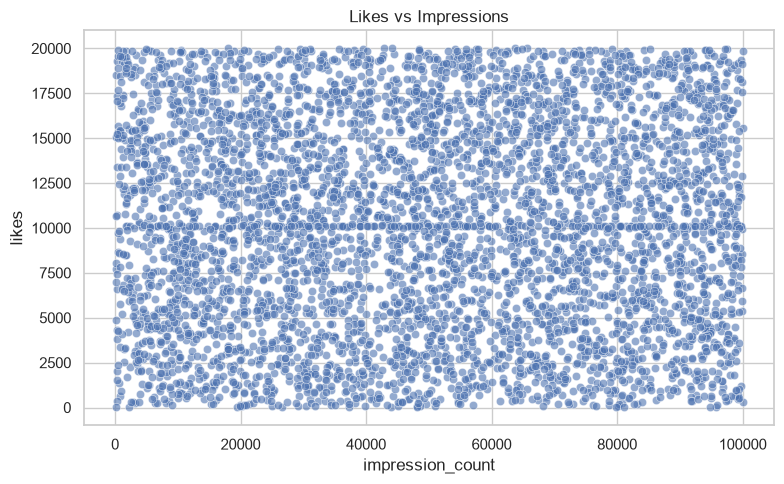

In [188]:
likes_col, impressions_col = COLUMN_MAP.get("likes"), COLUMN_MAP.get("impressions")
if likes_col and impressions_col:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=impressions_col, y=likes_col, alpha=0.6)
    plt.title("Likes vs Impressions")
    plt.tight_layout()
    plt.show()
else: print("Plot 1 skipped: likes or impressions column missing.")

In [194]:
date_col = COLUMN_MAP.get("date")
if date_col and "engagement_score" in df.columns:
    daily = df.dropna(subset=[date_col]).groupby(df[date_col].dt.date)["engagement_score"].mean()
    if not daily.empty:
        plt.figure(figsize=(10, 5))
        daily.plot()
        plt.title("Daily Average Engagement Score")
        plt.xlabel("Date")
        plt.ylabel("Average engagement score")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else: print("Plot 2 skipped: date or engagement_score missing.")

Plot 2 skipped: date or engagement_score missing.


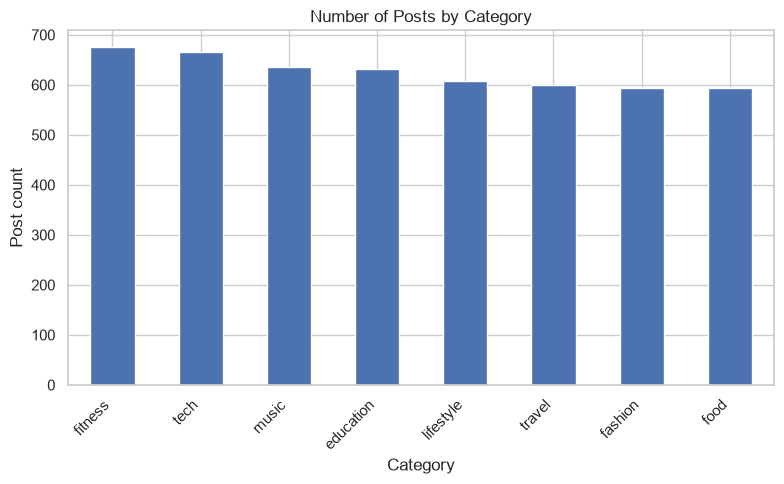

In [197]:
category_col = COLUMN_MAP.get("category")
if category_col:
    counts = df[category_col].value_counts().head(15)
    counts.plot(kind="bar", figsize=(8, 5))
    plt.title("Number of Posts by Category")
    plt.xlabel("Category")
    plt.ylabel("Post count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else: print("Plot 3 skipped: category column missing.")

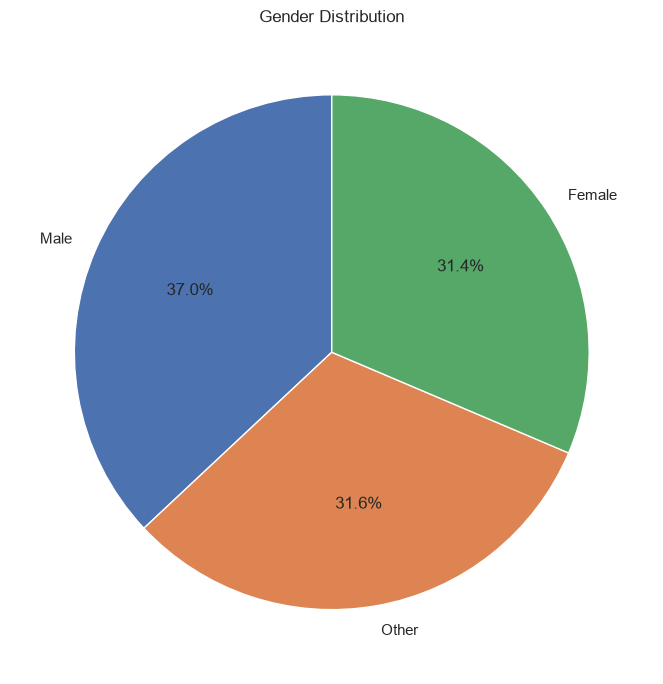

In [215]:
gender_col = COLUMN_MAP.get("gender")
if gender_col:
    gender_counts = df[gender_col].value_counts()
    if not gender_counts.empty:
        plt.figure(figsize=(7,7))
        plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", startangle=90)
        plt.title("Gender Distribution")
        plt.tight_layout()
        plt.show()
else: print("Plot 4 skipped: gender column missing.")

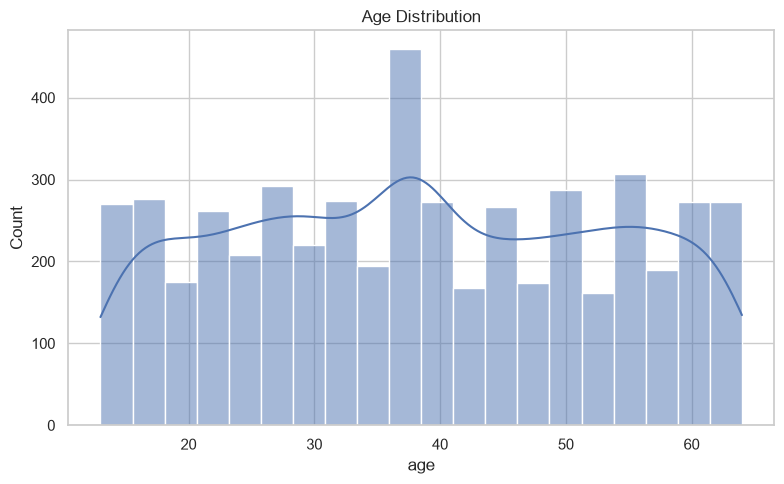

In [216]:
age_col = COLUMN_MAP.get("age")
if age_col:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df, x=age_col, bins=20, kde=True)
    plt.title("Age Distribution")
    plt.tight_layout()
    plt.show()
else: print("Plot 5 skipped: age column missing.")

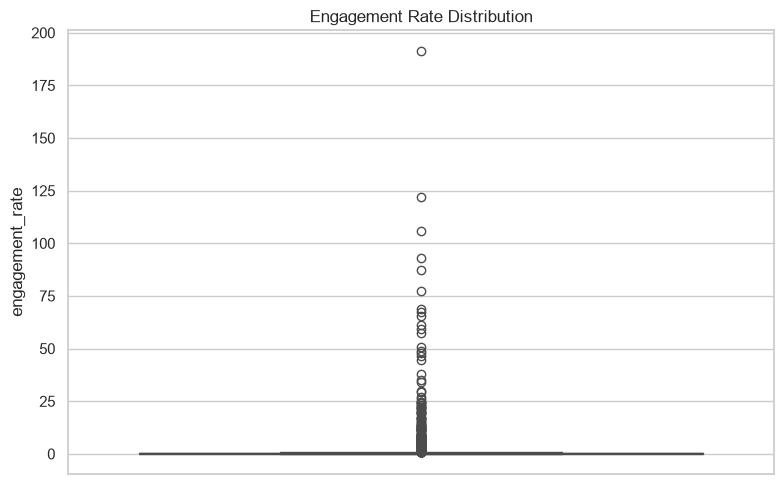

In [217]:
rate_col = COLUMN_MAP.get("engagement_rate")
if rate_col:
    plt.figure(figsize=(8,5))
    sns.boxplot(data=df, y=rate_col)
    plt.title("Engagement Rate Distribution")
    plt.tight_layout()
    plt.show()
else: print("Plot 6 skipped: engagement_rate column missing.")

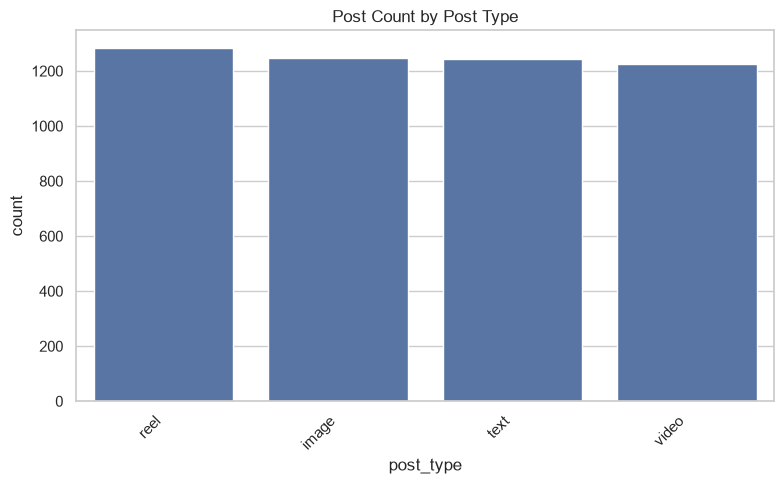

In [218]:
post_type_col = COLUMN_MAP.get("post_type")
if post_type_col:
    plt.figure(figsize=(8,5))
    order = df[post_type_col].value_counts().index
    sns.countplot(data=df, x=post_type_col, order=order)
    plt.title("Post Count by Post Type")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else: print("Plot 7 skipped: post_type column missing.")


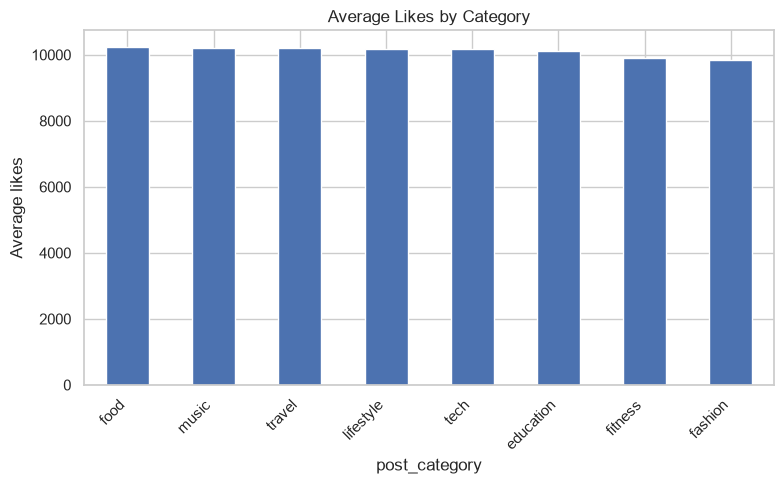

In [219]:
if category_col and likes_col:
    avg_likes = df.groupby(category_col)[likes_col].mean().sort_values(ascending=False).head(15)
    avg_likes.plot(kind="bar", figsize=(8,5))
    plt.title("Average Likes by Category")
    plt.ylabel("Average likes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else: print("Plot 8 skipped: category or likes column missing.")

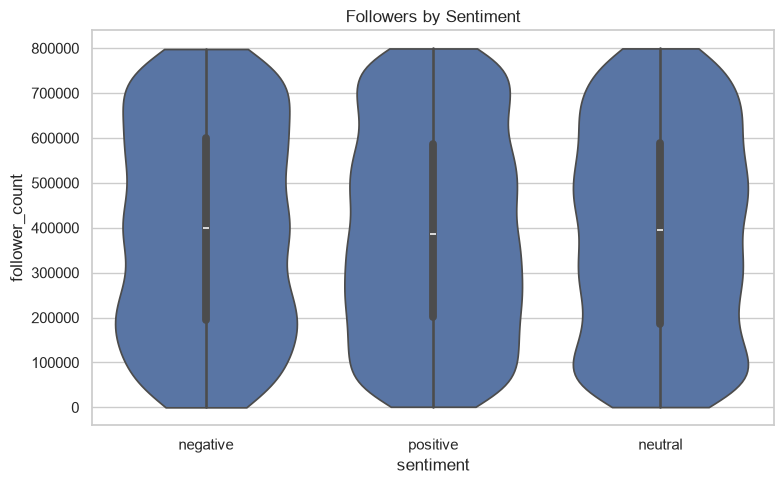

In [224]:
followers_col, sentiment_col = COLUMN_MAP.get("followers"), COLUMN_MAP.get("sentiment")
if followers_col and sentiment_col:
    plt.figure(figsize=(8,5))
    sns.violinplot(data=df, x=sentiment_col, y=followers_col, cut=0)
    plt.title("Followers by Sentiment")
    plt.tight_layout()
    plt.show()
else: print("Plot 9 skipped: followers or sentiment column missing.")


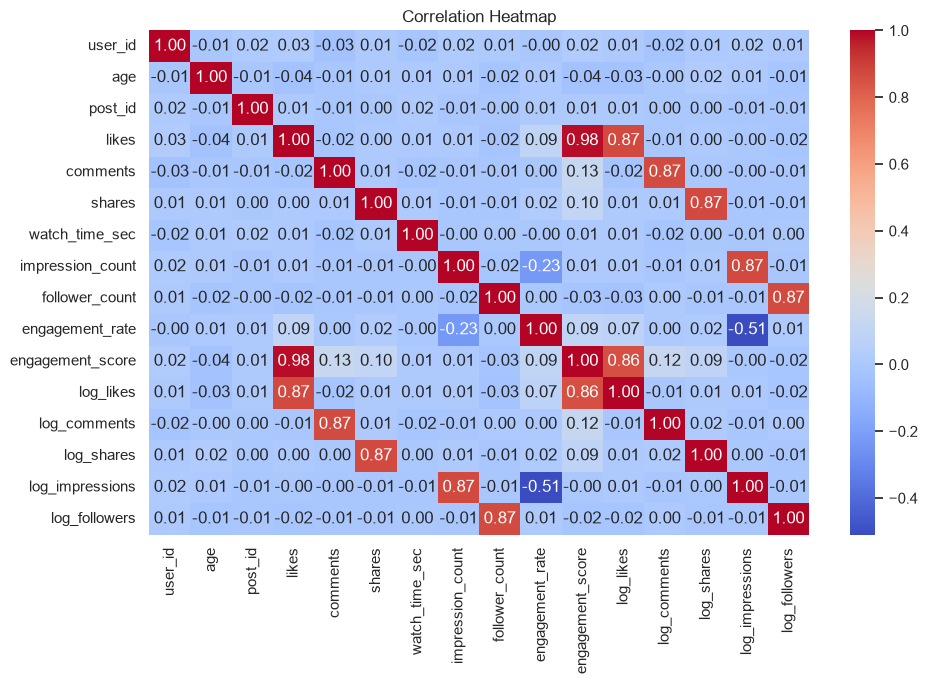

In [229]:
if len(numeric_df.columns) >= 2:
    plt.figure(figsize=(10,7))
    sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else: print("Plot 10 skipped: fewer than two numeric columns.")

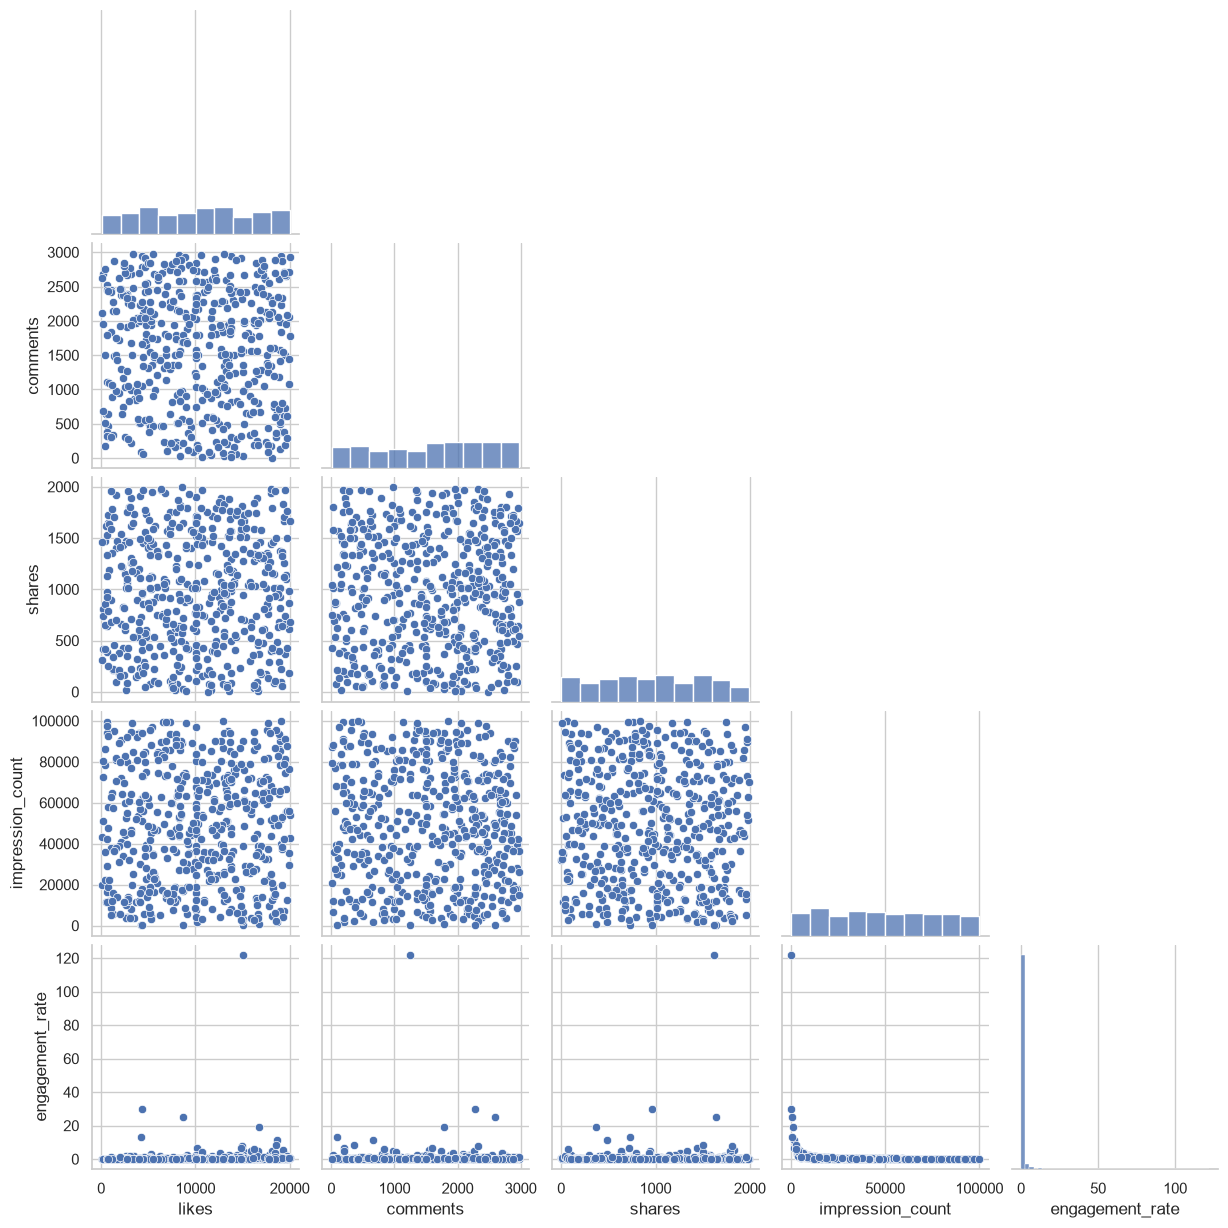

In [233]:
pair_cols = [COLUMN_MAP[k] for k in ["likes", "comments", "shares", "impressions", "engagement_rate"]if COLUMN_MAP.get(k) and COLUMN_MAP[k] in df.columns]
if len(pair_cols) >= 2:
    pair_data = df[pair_cols].dropna()
    if len(pair_data) > 500:
        pair_data = pair_data.sample(500, random_state=42)
    sns.pairplot(pair_data, corner=True)
    plt.show()
else: print("Pair plot skipped: need at least two numeric engagement fields.")

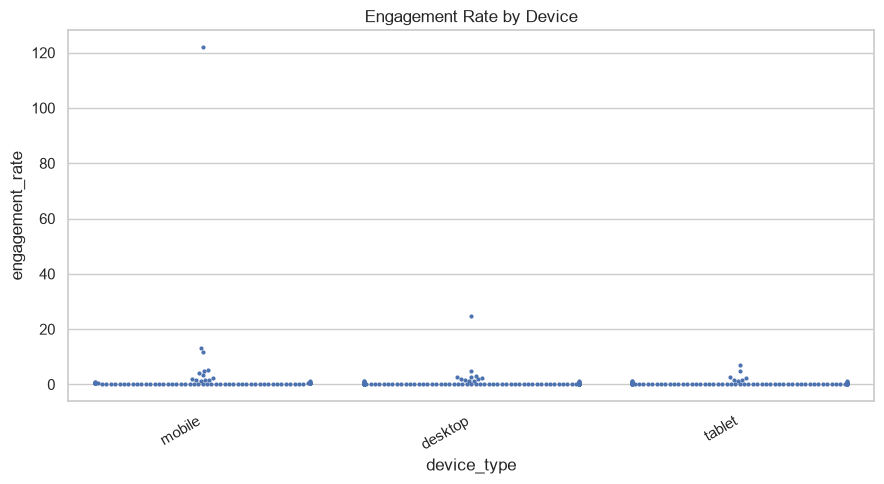

In [235]:
device_col = COLUMN_MAP.get("device")
if device_col and rate_col:
    swarm_data = df[[device_col, rate_col]].dropna()
    if len(swarm_data) > 300:
        swarm_data = swarm_data.sample(300, random_state=42)
    plt.figure(figsize=(9, 5))
    sns.swarmplot(data=swarm_data, x=device_col, y=rate_col, size=3)
    plt.title("Engagement Rate by Device")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else: print("Swarm plot skipped: device or engagement_rate column missing.")

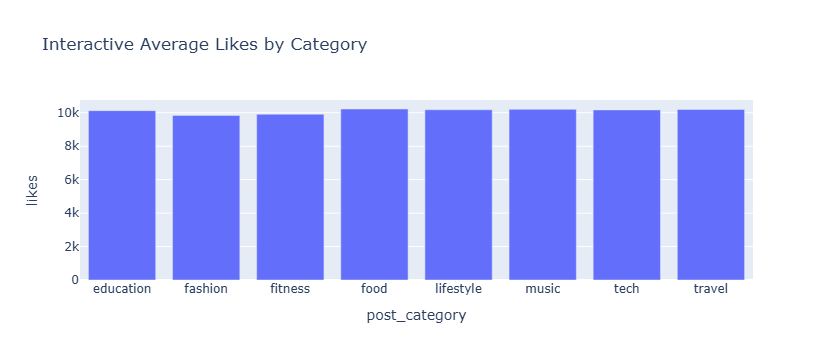

In [249]:
try:
    import plotly.express as px
    if date_col and "engagement_score" in df.columns:
        plot_df = df.dropna(subset=[date_col]).copy()
        plot_df["date_for_plot"] = plot_df[date_col].dt.date
        daily_plot = plot_df.groupby("date_for_plot", as_index=False)["engagement_score"].mean()
        fig = px.line(daily_plot, x="date_for_plot", y="engagement_score",
                      title="Interactive Daily Average Engagement Score",
                      labels={"date_for_plot": "Date", "engagement_score": "Average engagement score"})
        fig.show()
    elif category_col and likes_col:
        plot_data = df.groupby(category_col, as_index=False)[likes_col].mean()
        fig = px.bar(plot_data, x=category_col, y=likes_col, title="Interactive Average Likes by Category")
        fig.show()
    else:
        print("Plotly chart skipped: no suitable date/engagement or category/likes fields.")
except ImportError:
    print("Plotly is not installed. Run: %pip install plotly")

In [254]:
def top_group_average(group_field, metric_field, label):
    group_col = COLUMN_MAP.get(group_field)
    metric_col = COLUMN_MAP.get(metric_field)
    if group_col and metric_col:
        summary = df.groupby(group_col)[metric_col].mean().dropna().sort_values(ascending=False)
        if not summary.empty:
            print(f"{label}: {summary.index[0]} (average {metric_col} = {summary.iloc[0]:.2f})")
            display(summary.head(10).to_frame("average"))
        else: print(f"{label}: no usable data.")
    else: print(f"{label}: required columns not found.")

In [257]:
print("CONTENT PERFORMANCE")
top_group_average("post_type", "engagement_rate", "Post type with highest average engagement rate")
top_group_average("category", "engagement_rate", "Category with highest average engagement rate")
top_group_average("country", "engagement_rate", "Country with highest average engagement rate")

CONTENT PERFORMANCE
Post type with highest average engagement rate: video (average engagement_rate = 1.12)


,average
post_type,
video,1.122
text,1.065
image,0.896
reel,0.783


Category with highest average engagement rate: food (average engagement_rate = 1.36)


,average
post_category,
food,1.359
tech,1.160
lifestyle,1.091
music,0.889
fitness,0.866
education,0.844
fashion,0.807
travel,0.702


Country with highest average engagement rate: Brazil (average engagement_rate = 1.54)


,average
country,
Brazil,1.541
Australia,1.324
France,1.146
UAE,1.112
Canada,0.917
UK,0.851
Japan,0.770
Germany,0.759
India,0.655


In [258]:
print("\\nSENTIMENT")
top_group_average("sentiment", "engagement_rate", "Sentiment with highest average engagement rate")

\nSENTIMENT
Sentiment with highest average engagement rate: negative (average engagement_rate = 1.04)


,average
sentiment,
negative,1.038
neutral,0.991
positive,0.920


In [259]:
print("\\nDEVICE IMPACT")
top_group_average("device", "watch_time", "Device with highest average watch time")

\nDEVICE IMPACT
Device with highest average watch time: required columns not found.


In [267]:
print("\\nAGE AND ENGAGEMENT")
age_col, rate_col = COLUMN_MAP.get("age"), COLUMN_MAP.get("engagement_rate")
if age_col and rate_col:
    age_corr = df[[age_col, rate_col]].corr().iloc[0, 1]
    print(f"Correlation between age and engagement rate: {age_corr:.3f}")
    print("Interpretation: positive means the two tend to rise together; negative means one tends to decrease as the other rises. Correlation does not prove causation.")
else: print("Age/engagement relationship unavailable because a required column was not detected.")

\nAGE AND ENGAGEMENT
Correlation between age and engagement rate: 0.008
Interpretation: positive means the two tend to rise together; negative means one tends to decrease as the other rises. Correlation does not prove causation.


In [272]:
print("\nVERIFIED ACCOUNTS")
verified_col = COLUMN_MAP.get("verified")
if verified_col and rate_col:
    display(df.groupby(verified_col)[rate_col].agg(["count", "mean", "median"]).round(3))
else: print("Verified-account comparison unavailable because a required column was not detected.")


VERIFIED ACCOUNTS


,count,mean,median
is_verified,,,
False,4517,0.955,0.256
True,483,1.054,0.237


In [273]:
print("\nBEST TIME OF DAY FOR IMPRESSIONS")
time_col, imp_col = COLUMN_MAP.get("time_of_day"), COLUMN_MAP.get("impressions")
if time_col and imp_col:
    display(df.groupby(time_col)[imp_col].mean().sort_values(ascending=False).to_frame("average_impressions"))
else: print("Time-of-day analysis unavailable: no recognized time_of_day and/or impressions field.")


BEST TIME OF DAY FOR IMPRESSIONS
Time-of-day analysis unavailable: no recognized time_of_day and/or impressions field.


In [275]:
print("\nNEGATIVE AND NEUTRAL SENTIMENT")
if sentiment_col and rate_col:
    display(df[df[sentiment_col].isin(["negative", "neutral"])].groupby(sentiment_col)[rate_col].agg(["count", "mean", "median"]).round(3))
else:
    print("Negative/neutral sentiment analysis unavailable.")


NEGATIVE AND NEUTRAL SENTIMENT


,count,mean,median
sentiment,,,
negative,960,1.038,0.256
neutral,1527,0.991,0.252


In [295]:
report_lines = [
"SOCIAL MEDIA ENGAGEMENT ANALYTICS — SUMMARY",
    f"Cleaned dataset contains {len(df):,} rows and {df.shape[1]:,} columns.",
    f"Duplicate rows removed: {original_rows - len(df):,}."]
def report_top(group_field, metric_field, label):
    group_col, metric_col = COLUMN_MAP.get(group_field), COLUMN_MAP.get(metric_field)
    if group_col and metric_col:
        s = df.groupby(group_col)[metric_col].mean().dropna().sort_values(ascending=False)
    if not s.empty: report_lines.append(f"{label}: {s.index[0]} (mean {metric_col}: {s.iloc[0]:.2f}).")


In [296]:
report_top("post_type", "engagement_rate", "Highest-engagement post type")
report_top("category", "engagement_rate", "Top content category")
report_top("country", "engagement_rate", "Country with highest average engagement rate")
report_top("sentiment", "engagement_rate", "Best-performing sentiment")
report_top("device", "watch_time", "Device with highest average watch time")

UnboundLocalError: cannot access local variable 's' where it is not associated with a value

In [297]:
if age_col and rate_col:
    corr = df[[age_col, rate_col]].corr().iloc[0, 1]
    report_lines.append(f"Age vs engagement-rate correlation: {corr:.3f}.")

In [298]:
report_lines.append("Use the tables and charts above to explain patterns. These are associations in this dataset and do not establish causation.")
print("\\n".join("• " + line for line in report_lines))

• SOCIAL MEDIA ENGAGEMENT ANALYTICS — SUMMARY\n• Cleaned dataset contains 5,000 rows and 25 columns.\n• Duplicate rows removed: 0.\n• Highest-engagement post type: video (mean engagement_rate: 1.12).\n• Top content category: food (mean engagement_rate: 1.36).\n• Country with highest average engagement rate: Brazil (mean engagement_rate: 1.54).\n• Best-performing sentiment: negative (mean engagement_rate: 1.04).\n• Age vs engagement-rate correlation: 0.008.\n• Use the tables and charts above to explain patterns. These are associations in this dataset and do not establish causation.


In [291]:
OUTPUT_PATH = "social_media_engagement_cleaned.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"Cleaned dataset saved to: {OUTPUT_PATH}")

Cleaned dataset saved to: social_media_engagement_cleaned.csv
